# Roi Analysis

Owner: 

Input: 

Output: 

ROI Analysis
Objective
The objective of this analysis is to evaluate the effectiveness of marketing investments using Return on Investment (ROI) and Return on Advertising Spend (ROAS). This analysis identifies the effectiveness of marketing expenditures and provides insights for future marketing decisions.

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('default')
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv(
    "../data/processed/feature_engineered_marketing_mix_data.csv"
)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (36, 44)


,month,country,brand_category,region_scope,tv_spend_lkr,facebook_instagram_spend_lkr,google_search_spend_lkr,youtube_spend_lkr,radio_spend_lkr,outdoor_spend_lkr,...,revenue_per_unit,revenue_per_conversion,roas,cost_per_conversion,lag_1_total_spend,lag_2_total_spend,rolling_3_month_spend,marketing_pressure,competitive_advantage,promotion_impact
0,2023-01-01,Sri Lanka,FMCG - Packaged Foods,National,4274762.0,3890003.0,2467793.0,1836858.0,1700676.0,1813444.0,...,558.637776,57.943069,4.386643,13.208977,0.0,0.0,0.000000e+00,12469416.0,50.4,7.8516
1,2023-02-01,Sri Lanka,FMCG - Packaged Foods,National,4023574.0,5062635.0,2962576.0,2254198.0,1922384.0,2941194.0,...,633.780115,110.710778,3.839737,28.832909,15983536.0,0.0,0.000000e+00,14302983.0,49.0,9.0912
2,2023-03-01,Sri Lanka,FMCG - Packaged Foods,National,5359091.0,3746337.0,4080535.0,2363737.0,1720670.0,2063917.0,...,562.908050,223.483184,4.399608,50.796156,19166561.0,15983536.0,1.816146e+07,15549700.0,54.1,6.8300
3,2023-04-01,Sri Lanka,FMCG - Packaged Foods,National,5102550.0,3690115.0,3390558.0,2595121.0,1217450.0,3091430.0,...,533.883913,81.452943,5.242138,15.538116,19334287.0,19166561.0,1.919602e+07,14778344.0,68.8,25.6088
4,2023-05-01,Sri Lanka,FMCG - Packaged Foods,National,4972723.0,5333813.0,3240078.0,2343364.0,1568285.0,3525300.0,...,461.062423,137.662905,3.693476,37.271909,19087224.0,19334287.0,1.980169e+07,15889978.0,47.0,2.1450


MMM-Based Sales Prediction

In [3]:
import sys
sys.path.append('..')

import src.predict as predict

dir(predict)

['Any',
 'Dict',
 'List',
 'MMMPredictor',
 'Optional',
 'Path',
 'Tuple',
 'Union',
 '__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__loader__',
 '__name__',
 '__package__',
 '__spec__',
 'apply_adstock_with_carryover',
 'geometric_adstock',
 'hill_saturation',
 'joblib',
 'json',
 'np',
 'pd',
 'predict_sales']

In [4]:
from src.predict import MMMPredictor

predictor = MMMPredictor(
    model_path="../outputs/models/ridge_mmm_baseline.joblib",
    config_path="../outputs/models/model_config.json",
    transform_params_path="../outputs/models/transformation_params.json"
)

print(type(predictor))

<class 'src.predict.MMMPredictor'>


In [5]:
baseline_sales = predictor.predict(df)

print(baseline_sales[:5])

[73346245.94867855 78510021.18914725 82529973.84995429 96132369.6533272
 83671887.27663574]


In [6]:
df["baseline_sales"] = baseline_sales

baseline_total = baseline_sales.sum()

print(f"Total Predicted Sales: {baseline_total:,.2f}")

Total Predicted Sales: 3,064,139,339.54


Channel Contribution Analysis

In [7]:
channels = [
    'tv_spend_lkr',
    'facebook_instagram_spend_lkr',
    'google_search_spend_lkr',
    'youtube_spend_lkr',
    'radio_spend_lkr',
    'outdoor_spend_lkr'
]

results = []

for channel in channels:

    scenario = df.copy()

    scenario[channel] = 0

    sales_without_channel = (
        predictor.predict(scenario)
        .sum()
    )

    contribution = (
        baseline_total
        - sales_without_channel
    )

    spend = df[channel].sum()

    roi = contribution / spend

    results.append([
        channel,
        spend,
        contribution,
        roi
    ])

roi_df = pd.DataFrame(
    results,
    columns=[
        "Channel",
        "Spend",
        "Contribution",
        "ROI"
    ]
)

roi_df

,Channel,Spend,Contribution,ROI
0,tv_spend_lkr,156964242.0,3.663605e+08,2.334038
1,facebook_instagram_spend_lkr,158343617.0,1.690163e+08,1.067402
2,google_search_spend_lkr,119353135.0,4.607524e+08,3.860413
3,youtube_spend_lkr,79913729.0,3.393820e+08,4.246855
4,radio_spend_lkr,60107999.0,0.000000e+00,0.000000
5,outdoor_spend_lkr,94057802.0,1.916657e+08,2.037743


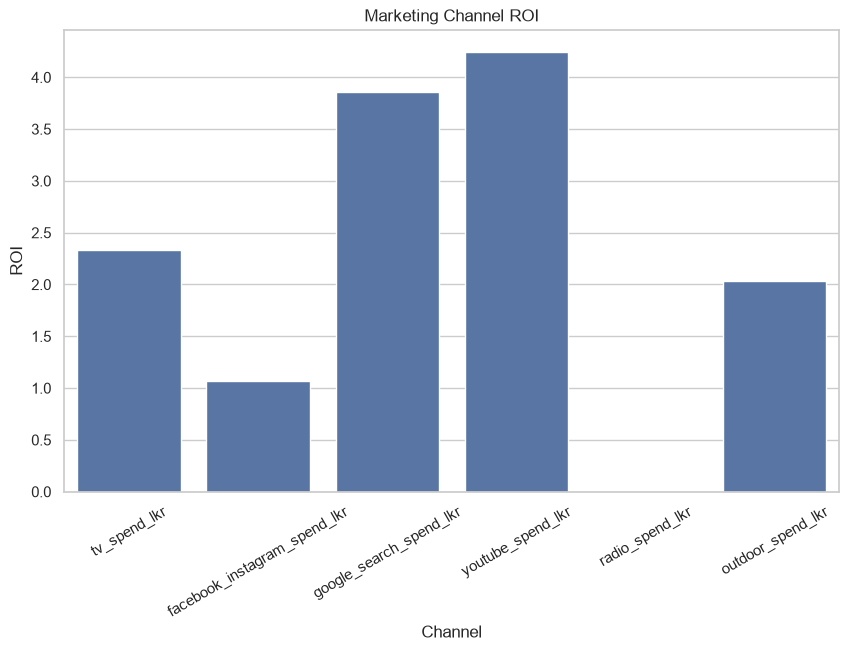

In [8]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=roi_df,
    x="Channel",
    y="ROI"
)

plt.title("Marketing Channel ROI")
plt.xticks(rotation=30)

plt.show()

In [9]:
best_channel = roi_df.loc[roi_df["ROI"].idxmax()]
worst_channel = roi_df.loc[roi_df["ROI"].idxmin()]

print("Best Performing Channel")
print(best_channel)

print("\nWorst Performing Channel")
print(worst_channel)

Best Performing Channel
Channel         youtube_spend_lkr
Spend                  79913729.0
Contribution     339381997.657371
ROI                      4.246855
Name: 3, dtype: object

Worst Performing Channel
Channel         radio_spend_lkr
Spend                60107999.0
Contribution                0.0
ROI                         0.0
Name: 4, dtype: object


## Setup for the new sections
Folder paths for saving, readable channel names, and the `month` column as a date.

In [10]:
from pathlib import Path

TABLES = Path("../outputs/tables"); TABLES.mkdir(parents=True, exist_ok=True)
FIGURES = Path("../outputs/figures"); FIGURES.mkdir(parents=True, exist_ok=True)

df["month"] = pd.to_datetime(df["month"])

NICE = {"tv_spend_lkr": "TV", "facebook_instagram_spend_lkr": "Facebook/Instagram",
        "google_search_spend_lkr": "Google Search", "youtube_spend_lkr": "YouTube",
        "radio_spend_lkr": "Radio", "outdoor_spend_lkr": "Outdoor"}

# channels with a negative model coefficient (a model issue, not a business finding)
coefs = pd.Series(predictor.model.named_steps["regression"].coef_, index=predictor.features)
NEGATIVE = [ch for ch in channels if coefs[f"{ch}_hill"] < 0]
print("Channels with a negative model coefficient:", [NICE[c] for c in NEGATIVE])

Channels with a negative model coefficient: []


## Base Sales vs Channel Contributions
For each channel we switch its spend off (set to 0) and see how much predicted sales drop each month.
That drop is the channel's **contribution**. What is left after removing all six channels is **base sales** —
the sales that would happen even with no advertising.

Channel Spending Analysis
This section examines how advertising budgets were distributed across different marketing channels.

In [11]:
contrib = pd.DataFrame({"month": df["month"]})
for ch in channels:
    cf = predictor.predict_counterfactual(df, spend_multipliers={ch: 0.0})
    contrib[ch] = -cf["delta_sales_lkr"].values          # sales caused by this channel, per month

contrib["base"] = baseline_sales - contrib[channels].sum(axis=1)

base_share = contrib["base"].sum() / baseline_sales.sum() * 100
print(f"Base sales     : {base_share:.1f}% of predicted sales")
print(f"Media-driven   : {100 - base_share:.1f}% of predicted sales")

# save in long format (one row per month and component) for Power BI
contributions = contrib.rename(columns={**NICE, "base": "Base"}).melt(
    id_vars="month", var_name="component", value_name="contribution_lkr")
contributions["component_type"] = np.where(contributions["component"] == "Base", "Base", "Media")
contributions = contributions.merge(
    pd.DataFrame({"month": df["month"], "sales_revenue_lkr": df["sales_revenue_lkr"],
                  "predicted_sales_lkr": baseline_sales}), on="month")
contributions["month"] = contributions["month"].dt.strftime("%Y-%m-%d")
contributions.to_csv(TABLES / "contributions.csv", index=False)
print("Saved contributions.csv:", contributions.shape)

Base sales     : 50.2% of predicted sales
Media-driven   : 49.8% of predicted sales


Saved contributions.csv: (252, 6)


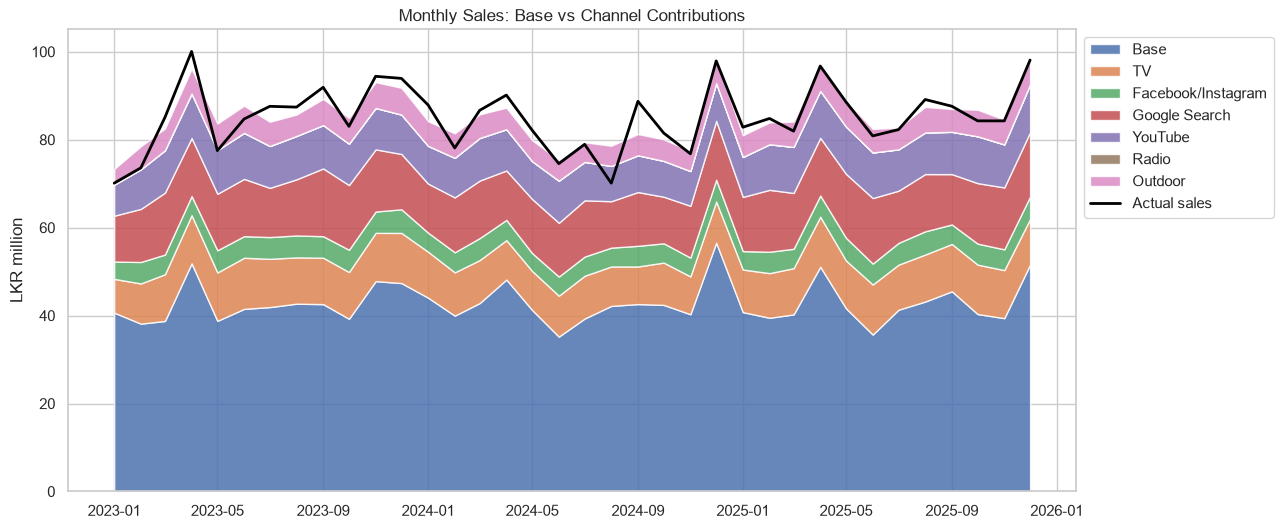

In [12]:
fig, ax = plt.subplots(figsize=(13, 6))
positive = [c for c in channels if c not in NEGATIVE]
stack = contrib[["base"] + positive].clip(lower=0) / 1e6
ax.stackplot(contrib["month"], stack.T.values, labels=["Base"] + [NICE[c] for c in positive], alpha=0.85)
for c in NEGATIVE:
    ax.fill_between(contrib["month"], contrib[c] / 1e6, 0, color="grey", alpha=0.6,
                    label=f"{NICE[c]} (negative - model issue)")
ax.plot(df["month"], df["sales_revenue_lkr"] / 1e6, color="black", lw=2, label="Actual sales")
ax.set(title="Monthly Sales: Base vs Channel Contributions", ylabel="LKR million")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.savefig(FIGURES / "roi_01_sales_decomposition.png", dpi=150, bbox_inches="tight")
plt.show()

## Marginal ROI
ROI is the **average** return. Marginal ROI is the return on the **next** rupee: we raise one channel's spend by 1%
and see how much extra sales the model predicts. Above 1 → more spend still pays back. Below 1 → the channel already gets too much.

In [13]:
mroi = {}
for ch in channels:
    bump = predictor.predict_counterfactual(df, spend_multipliers={ch: 1.01})
    mroi[ch] = bump["delta_sales_lkr"].sum() / (0.01 * df[ch].sum())

roi_table = pd.DataFrame({
    "channel": [NICE[c] for c in roi_df["Channel"]],
    "channel_column": roi_df["Channel"],
    "total_spend_lkr": roi_df["Spend"],
    "incremental_sales_lkr": roi_df["Contribution"],
    "roas_incremental": roi_df["ROI"],
    "roi_pct": (roi_df["Contribution"] - roi_df["Spend"]) / roi_df["Spend"] * 100,
    "marginal_roi": roi_df["Channel"].map(mroi),
})
roi_table["spend_share_pct"] = roi_table["total_spend_lkr"] / roi_table["total_spend_lkr"].sum() * 100
roi_table["contribution_share_pct"] = (roi_table["incremental_sales_lkr"]
                                       / roi_table["incremental_sales_lkr"].clip(lower=0).sum() * 100)
roi_table["model_sign_ok"] = ~roi_table["channel_column"].isin(NEGATIVE)
roi_table = roi_table.sort_values("marginal_roi", ascending=False).reset_index(drop=True)
roi_table.insert(0, "rank", range(1, len(roi_table) + 1))

roi_table.to_csv(TABLES / "roi_table.csv", index=False)
print("Saved roi_table.csv")
roi_table[["rank", "channel", "roas_incremental", "marginal_roi", "spend_share_pct", "contribution_share_pct"]].round(2)

Saved roi_table.csv


,rank,channel,roas_incremental,marginal_roi,spend_share_pct,contribution_share_pct
0,1,YouTube,4.25,2.09,11.95,22.22
1,2,Google Search,3.86,1.89,17.85,30.17
2,3,TV,2.33,1.16,23.47,23.99
3,4,Outdoor,2.04,1.00,14.06,12.55
4,5,Facebook/Instagram,1.07,0.53,23.68,11.07
5,6,Radio,0.00,0.00,8.99,0.00


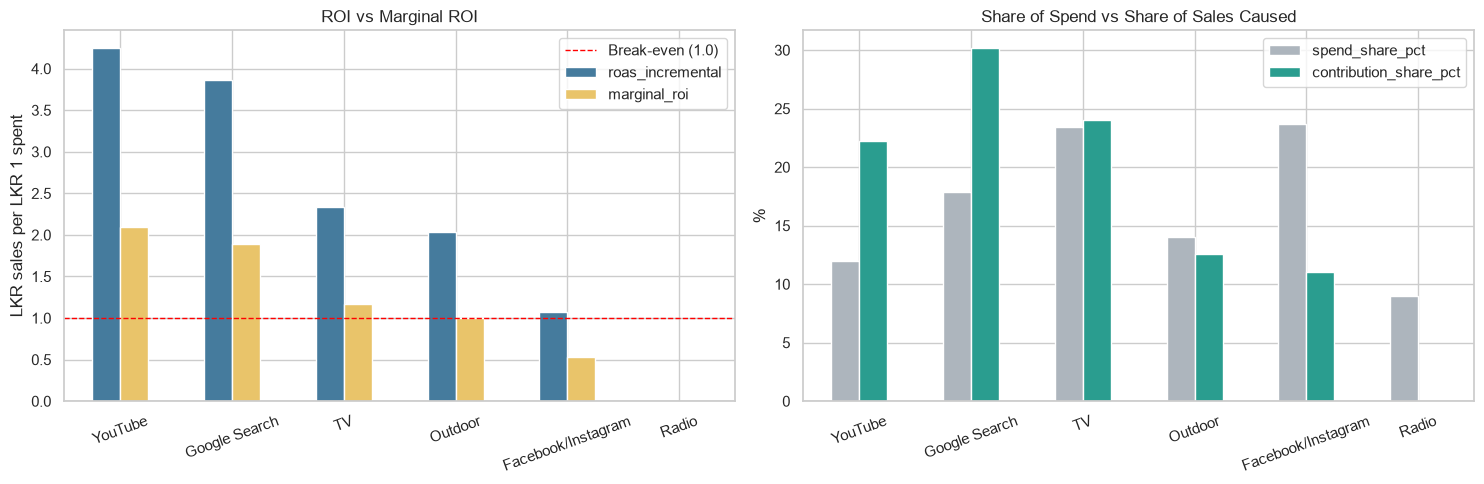

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
r = roi_table.set_index("channel")
r[["roas_incremental", "marginal_roi"]].plot(kind="bar", ax=axes[0], color=["#457b9d", "#e9c46a"], rot=20)
axes[0].axhline(1, color="red", ls="--", lw=1, label="Break-even (1.0)")
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set(title="ROI vs Marginal ROI", ylabel="LKR sales per LKR 1 spent", xlabel=""); axes[0].legend()

r[["spend_share_pct", "contribution_share_pct"]].plot(kind="bar", ax=axes[1], color=["#adb5bd", "#2a9d8f"], rot=20)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(title="Share of Spend vs Share of Sales Caused", ylabel="%", xlabel="")
fig.tight_layout()
fig.savefig(FIGURES / "roi_02_roi_by_channel.png", dpi=150, bbox_inches="tight")
plt.show()

## Response Curves (Diminishing Returns)
For each channel we change its **2025** spend from 0× to 2× (other channels unchanged) and record the extra sales.
2024's leftover ad effect (carry-over) is passed in so the time delay is handled correctly.
Where the curve flattens, extra money is mostly wasted.

In [15]:
hist = df[df["month"] < "2025-01-01"]
plan = df[df["month"] >= "2025-01-01"].reset_index(drop=True)
_, carry_2024 = predictor.predict(hist, return_carryover=True)

def plan_sales(multipliers):
    d = plan.copy()
    for ch, m in multipliers.items():
        d[ch] = plan[ch] * m
    return predictor.predict(d, initial_carryover=carry_2024).sum()

grid = np.round(np.arange(0, 2.01, 0.05), 2)
rows = []
for ch in channels:
    zero = plan_sales({ch: 0.0})
    for m in grid:
        rows.append({"channel": NICE[ch], "spend_multiplier": m,
                     "annual_spend_lkr": plan[ch].sum() * m,
                     "incremental_sales_lkr": plan_sales({ch: m}) - zero,
                     "is_current_spend": m == 1.0})
response_curves = pd.DataFrame(rows)
response_curves["marginal_roi"] = (response_curves.groupby("channel")["incremental_sales_lkr"].diff()
                                   / response_curves.groupby("channel")["annual_spend_lkr"].diff())
response_curves.to_csv(TABLES / "response_curves.csv", index=False)
print("Saved response_curves.csv:", response_curves.shape)

Saved response_curves.csv: (246, 6)


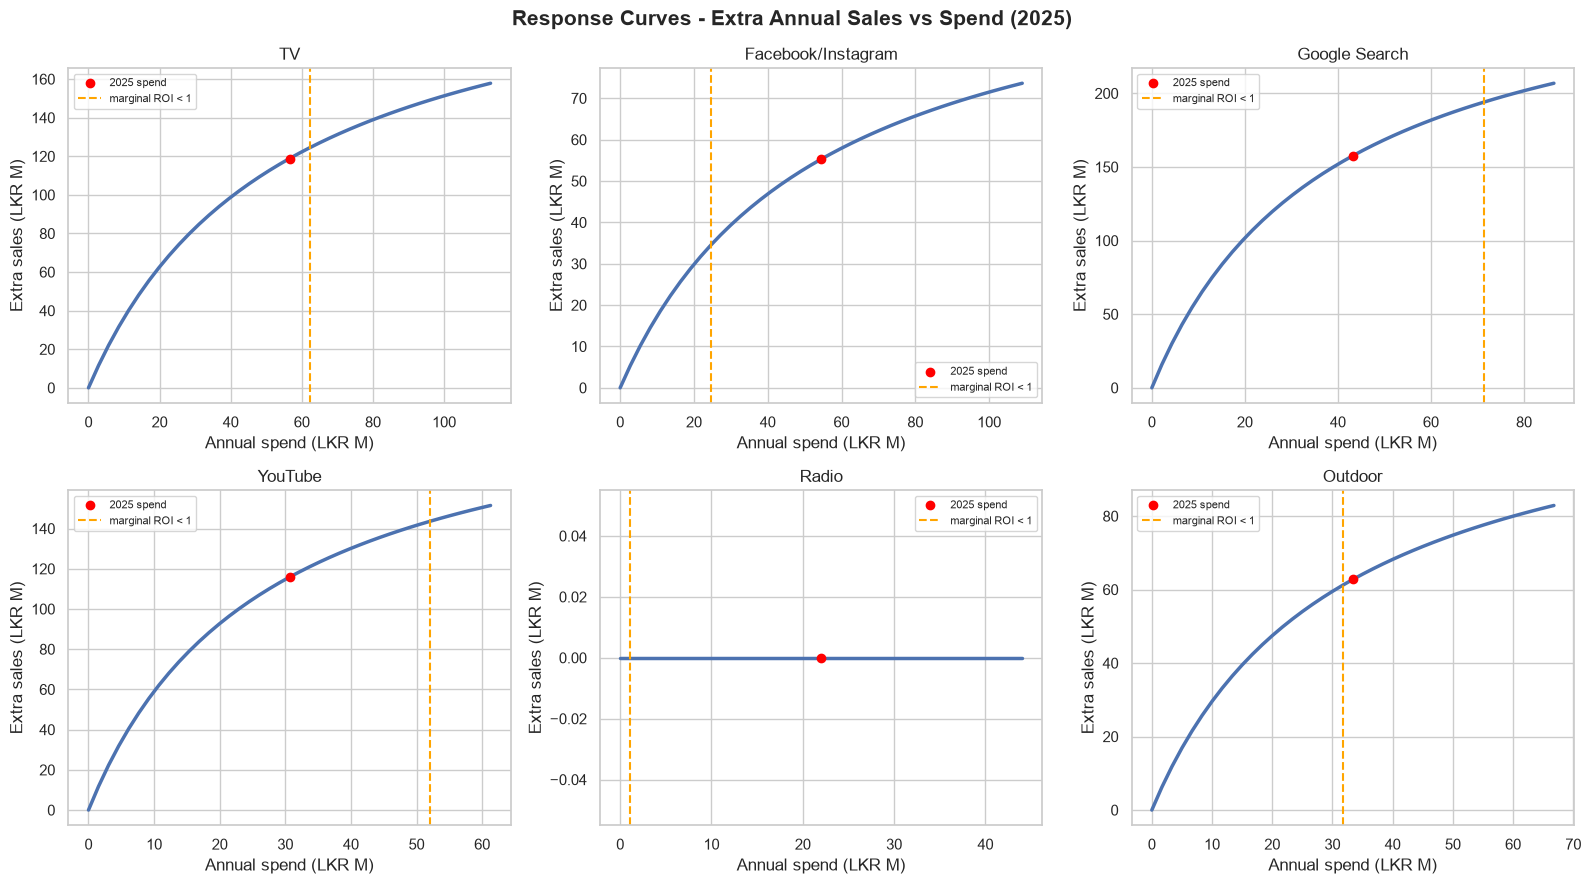

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, ch in zip(axes.ravel(), channels):
    c = response_curves[response_curves["channel"] == NICE[ch]]
    ax.plot(c["annual_spend_lkr"] / 1e6, c["incremental_sales_lkr"] / 1e6, lw=2.5)
    cur = c[c["is_current_spend"]].iloc[0]
    ax.scatter(cur["annual_spend_lkr"] / 1e6, cur["incremental_sales_lkr"] / 1e6, color="red", zorder=5, label="2025 spend")
    below = c[(c["marginal_roi"] < 1) & (c["spend_multiplier"] > 0)]
    if ch not in NEGATIVE and len(below):
        ax.axvline(below["annual_spend_lkr"].iloc[0] / 1e6, color="orange", ls="--", label="marginal ROI < 1")
    ax.set(title=NICE[ch], xlabel="Annual spend (LKR M)", ylabel="Extra sales (LKR M)")
    ax.legend(fontsize=8)
fig.suptitle("Response Curves - Extra Annual Sales vs Spend (2025)", fontsize=15, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "roi_03_response_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## External Factor Impact
External factors have no sensible zero (a price index of 0 is impossible), so we compare each factor with its **average** level.
We report the effect of a normal-sized change (+1 standard deviation) and a few easy examples.

**Note:** `average_price_index` and `inflation_proxy_index` move together (VIF ≈ 100 in the EDA), so read them together, not one by one.

In [17]:
avg_sales = baseline_sales.mean()
ext_rows = []
ext_monthly = pd.DataFrame({"month": df["month"]})
for f in predictor.external_factors:
    at_mean = df.copy(); at_mean[f] = df[f].mean()
    effect = baseline_sales - predictor.predict(at_mean)
    ext_monthly[f] = effect
    plus = df.copy(); plus[f] = df[f] + df[f].std()
    one_sd = (predictor.predict(plus) - baseline_sales).mean()
    ext_rows.append({"factor": f, "std_dev": df[f].std(),
                     "effect_of_plus_1_std_lkr": one_sd,
                     "effect_of_plus_1_std_pct": one_sd / avg_sales * 100,
                     "avg_abs_monthly_effect_lkr": np.abs(effect).mean(),
                     "direction": "increases sales" if one_sd > 0 else "reduces sales",
                     "collinear_warning": f in ["average_price_index", "inflation_proxy_index"]})
external_impact = (pd.DataFrame(ext_rows)
                   .sort_values("avg_abs_monthly_effect_lkr", ascending=False).reset_index(drop=True))
external_impact.to_csv(TABLES / "external_impact.csv", index=False)
print("Saved external_impact.csv")

# easy examples for the report
dec = df["month"].dt.month == 12
print(f"December festive season adds about LKR {ext_monthly.loc[dec, 'seasonal_demand_index'].mean()/1e6:.1f}M per month")
for f, step, label in [("promotion_discount_pct", 5, "+5 points of promotion discount"),
                       ("competitor_pressure_index_0_100", 10, "+10 points of competitor pressure")]:
    d = df.copy(); d[f] = df[f] + step
    eff = (predictor.predict(d) - baseline_sales).mean()
    print(f"{label}: LKR {eff/1e6:+.2f}M per month ({eff/avg_sales*100:+.1f}%)")
external_impact[["factor", "effect_of_plus_1_std_lkr", "effect_of_plus_1_std_pct", "direction"]].round(2)

Saved external_impact.csv
December festive season adds about LKR 5.3M per month
+5 points of promotion discount: LKR +2.15M per month (+2.5%)
+10 points of competitor pressure: LKR -0.84M per month (-1.0%)


,factor,effect_of_plus_1_std_lkr,effect_of_plus_1_std_pct,direction
0,promotion_discount_pct,2579518.71,3.03,increases sales
1,seasonal_demand_index,2497514.10,2.93,increases sales
2,economic_sentiment_index_0_100,877878.93,1.03,increases sales
3,competitor_pressure_index_0_100,-857944.40,-1.01,reduces sales
4,inflation_proxy_index,586896.90,0.69,increases sales
5,average_price_index,545797.19,0.64,increases sales
6,lkr_usd_exchange_rate,-268791.57,-0.32,reduces sales
7,public_holiday_count,135850.22,0.16,increases sales


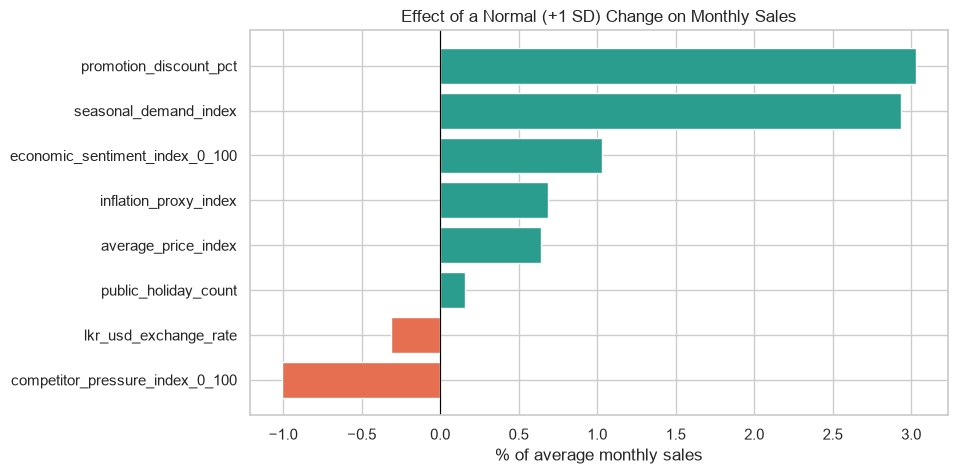

In [18]:
e = external_impact.set_index("factor")["effect_of_plus_1_std_pct"].sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(e.index, e.values, color=np.where(e.values > 0, "#2a9d8f", "#e76f51"))
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Effect of a Normal (+1 SD) Change on Monthly Sales", xlabel="% of average monthly sales")
fig.savefig(FIGURES / "roi_04_external_impact.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
channel_cols = [
    'tv_spend_lkr',
    'facebook_instagram_spend_lkr',
    'google_search_spend_lkr',
    'youtube_spend_lkr',
    'radio_spend_lkr',
    'outdoor_spend_lkr'
]

channel_spend = df[channel_cols].sum()

channel_spend.sort_values(
    ascending=False
)

facebook_instagram_spend_lkr    158343617.0
tv_spend_lkr                    156964242.0
google_search_spend_lkr         119353135.0
outdoor_spend_lkr                94057802.0
youtube_spend_lkr                79913729.0
radio_spend_lkr                  60107999.0
dtype: float64

## Key Findings

- **Base sales:** About **50.2%** of predicted sales would happen even without advertising. Advertising drives about **49.8%** of sales.
- **Best channels by marginal ROI** (return on the next LKR 1):
  - **YouTube** – ROI 4.25, marginal ROI **2.09**
  - **Google Search** – ROI 3.86, marginal ROI **1.89**
  - **TV** – ROI 2.33, marginal ROI 1.16
  - **Outdoor** – ROI 2.04, marginal ROI 1.00
- **Facebook/Instagram** has the lowest marginal ROI among channels with an effect (**0.53**). This is below 1, so the last rupees spent there bring back less than a rupee in sales.
- **Under-funded channels:** YouTube (12% of spend, 22% of sales caused) and Google Search (18% of spend, 30% of sales caused) bring in more than their share of the budget.
- **Over-funded channel:** Facebook/Instagram receives about 24% of spend but causes only about 11% of the sales from advertising.
- **Response curves:** TV, Google Search and YouTube still have room to grow. Outdoor is at its break-even point, and Facebook/Instagram is well past it.
- **External factors:** Promotions and seasonality move sales the most, followed by economic sentiment. The December festive season adds about **LKR 5.3M** per month, and a 5-point higher promotion discount adds about **LKR 2.2M (+2.5%)** per month. Higher competitor pressure reduces sales (about -1.0% for +10 points).
- **Radio:** The model finds **no measurable sales effect** from Radio (ROI 0.00). Media effects are constrained to be zero or positive, so Radio is shown as having no detectable effect rather than a harmful one.

## Recommendations

- **Increase investment in YouTube and Google Search.** They have the highest marginal ROI and bring in more sales than their share of the budget.
- **Reduce Facebook/Instagram spend.** Its marginal ROI is below 1, so part of its budget would earn more in other channels.
- **Keep TV at about its current level or increase it slightly.** It still returns more than LKR 1 per extra rupee.
- **Hold Outdoor steady.** It is at its break-even point, so extra spend would only just pay for itself.
- **Review Radio.** The model cannot detect a sales effect from Radio in this data. Before cutting it heavily, test it in practice (for example a regional on/off test) or reduce it gradually and watch sales.
- **Plan campaigns around promotions and festive seasons,** since these drive sales more strongly than any single media channel.
- Use these ROI and marginal ROI results as the input for budget optimisation (Notebook 07).

## Conclusion

Using the Marketing Mix Model with non-negative media effects, total sales were split into base sales and the contribution of each channel. About half of sales is driven by advertising. YouTube and Google Search give the highest return on additional spend, while Facebook/Instagram is well past its break-even point. Promotions and seasonality are the strongest external drivers of sales. The model finds no measurable effect from Radio, which should be confirmed with a real-world test before major changes. These findings provide the basis for the budget optimisation in Notebook 07.